# Analyse du dataset MM-Fi

## 0 - imports

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


DATA_DIR = Path("data")
MMFI_DIR = DATA_DIR / "MMFi_lidar_only" / "MMFi_Dataset"

print(f"MMFi dataset: {MMFI_DIR.resolve()}")
print(f"Dataset exists: {MMFI_DIR.exists()}")


MMFi dataset: C:\Users\mbonn\LIARA_2026_internship\data\MMFi_lidar_only\MMFi_Dataset
Dataset exists: True


## 1 - load data

In [2]:
# Return sequence directories containing LiDAR frames

def list_sequences(dataset_dir=MMFI_DIR):
    return sorted(
        action_dir
        for action_dir in dataset_dir.glob("E*/S*/A*")
        if (action_dir / "lidar").is_dir()
    )

In [3]:
sequence_dirs = list_sequences()

In [4]:
sequence_index = pd.DataFrame(
    [
        {
            "environment": path.parts[-3],
            "subject": path.parts[-2],
            "action": path.parts[-1],
            "path": path,
            "frames": len(list((path / "lidar").glob("frame*.bin"))),
        }
        for path in sequence_dirs
    ]
)

In [5]:
sample_sequence = sequence_dirs[0]

In [6]:
# Load one MMFi LiDAR frame as an (N, 3) float64 XYZ array

def load_lidar_frame(frame_path):
    values = np.fromfile(frame_path, dtype=np.float64)
    if values.size % 3 != 0:
        raise ValueError(f"Unexpected point count in {frame_path}: {values.size}")
    return values.reshape(-1, 3)

In [7]:
# Load all LiDAR frames and the aligned (T, 17, 3) ground truth

def load_sequence(sequence_dir):
    sequence_dir = Path(sequence_dir)
    frame_paths = sorted((sequence_dir / "lidar").glob("frame*.bin"))
    frames = [load_lidar_frame(path) for path in frame_paths]
    ground_truth = np.load(sequence_dir / "ground_truth.npy", allow_pickle=False)
    if len(frames) != len(ground_truth):
        raise ValueError(
            f"Frame/ground-truth mismatch in {sequence_dir}: "
            f"{len(frames)} frames vs {len(ground_truth)} annotations"
        )
    return frames, ground_truth

In [8]:
sample_frames, sample_ground_truth = load_sequence(sample_sequence)

In [9]:
print(f"Sequences found: {len(sequence_index)}")
print(f"Sample sequence: {sample_sequence.relative_to(DATA_DIR)}")
print(f"Sample frames: {len(sample_frames)}; first frame shape: {sample_frames[0].shape}")
print(f"Ground truth shape: {sample_ground_truth.shape}")
sequence_index.head()

Sequences found: 1080
Sample sequence: MMFi_lidar_only\MMFi_Dataset\E01\S01\A01
Sample frames: 297; first frame shape: (1134, 3)
Ground truth shape: (297, 17, 3)


,environment,subject,action,path,frames
0,E01,S01,A01,data\MMFi_lidar_only\MMFi_Dataset\E01\S01\A01,297
1,E01,S01,A02,data\MMFi_lidar_only\MMFi_Dataset\E01\S01\A02,297
2,E01,S01,A03,data\MMFi_lidar_only\MMFi_Dataset\E01\S01\A03,297
3,E01,S01,A04,data\MMFi_lidar_only\MMFi_Dataset\E01\S01\A04,297
4,E01,S01,A05,data\MMFi_lidar_only\MMFi_Dataset\E01\S01\A05,297


## 2 - class distribution

In [11]:
action_names = {
    "A01": "Stretching and relaxing",
    "A02": "Chest expansion (horizontal)",
    "A03": "Chest expansion (vertical)",
    "A04": "Twist (left)",
    "A05": "Twist (right)",
    "A06": "Mark time",
    "A07": "Limb extension (left)",
    "A08": "Limb extension (right)",
    "A09": "Lunge (toward left-front)",
    "A10": "Lunge (toward right-front)",
    "A11": "Limb extension (both)",
    "A12": "Squat",
    "A13": "Raising hand (left)",
    "A14": "Raising hand (right)",
    "A15": "Lunge (toward left)",
    "A16": "Lunge (toward right)",
    "A17": "Waving hand (left)",
    "A18": "Waving hand (right)",
    "A19": "Picking up things",
    "A20": "Throwing (toward left)",
    "A21": "Throwing (toward right)",
    "A22": "Kicking (toward left)",
    "A23": "Kicking (toward right)",
    "A24": "Body extension (left)",
    "A25": "Body extension (right)",
    "A26": "Jumping up",
    "A27": "Bowing",
}

In [ ]:
class_distribution = (
    sequence_index.assign(class_name=sequence_index["action"].map(action_names))
    .groupby(["action", "class_name"], sort=True)
    .agg(sequences=("action", "size"), frames=("frames", "sum"))
)

Number of classes: 27
Total sequences: 1080


,action,class_name,sequences,frames
0,A01,Stretching and relaxing,40,11880
1,A02,Chest expansion (horizontal),40,11880
2,A03,Chest expansion (vertical),40,11880
3,A04,Twist (left),40,11880
4,A05,Twist (right),40,11880
5,A06,Mark time,40,11880
6,A07,Limb extension (left),40,11880
7,A08,Limb extension (right),40,11880
8,A09,Lunge (toward left-front),40,11880
9,A10,Lunge (toward right-front),40,11880


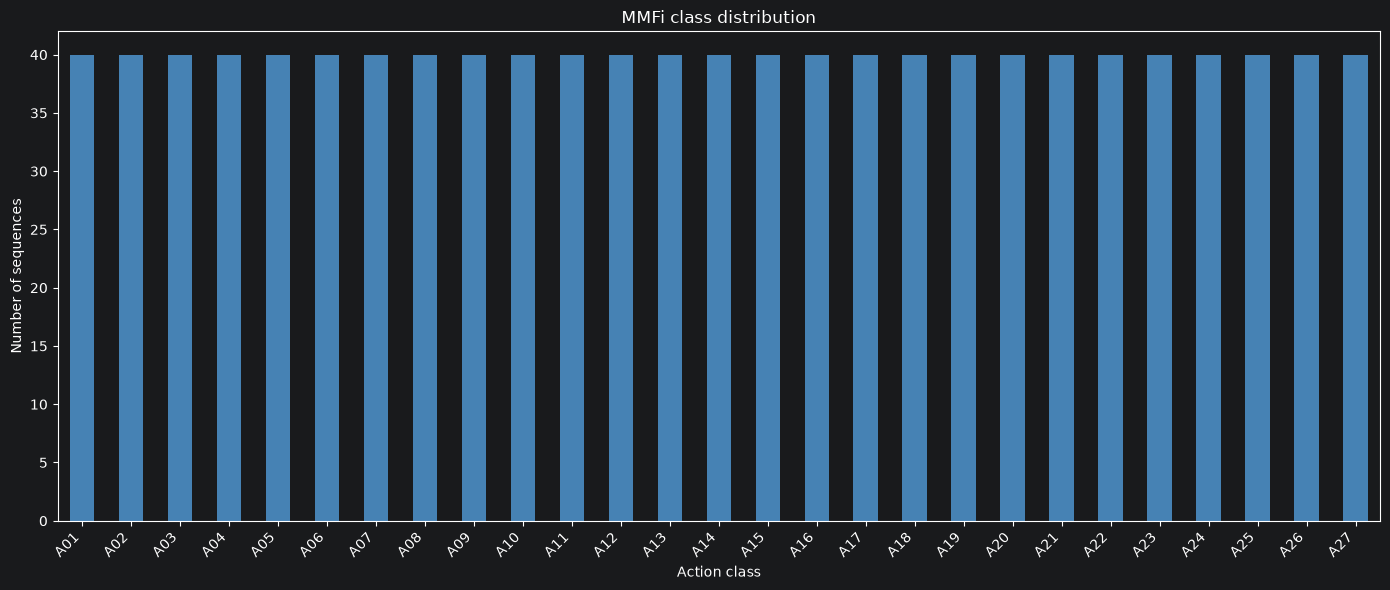

In [15]:
print(f"Number of classes: {len(class_distribution)}")
print(f"Total sequences: {class_distribution['sequences'].sum()}")
display(class_distribution.reset_index())

fig, ax = plt.subplots(figsize=(14, 6))
class_distribution["sequences"].plot.bar(ax=ax, color="steelblue")
ax.set_title("MMFi class distribution")
ax.set_xlabel("Action class")
ax.set_ylabel("Number of sequences")
ax.set_xticklabels(
    [code for code, _ in class_distribution.index],
    rotation=45,
    ha="right",
)
fig.tight_layout()
plt.show()

## 3 - data quality and point-cloud statistics

In [ ]:
def inspect_frame(frame_path):
    points = load_lidar_frame(frame_path)
    finite = np.isfinite(points).all(axis=1)
    finite_points = points[finite]
    distances = np.linalg.norm(finite_points, axis=1)

    return {
        "points": len(points),
        "finite_points": int(finite.sum()),
        "min_x": finite_points[:, 0].min() if len(finite_points) else np.nan,
        "max_x": finite_points[:, 0].max() if len(finite_points) else np.nan,
        "min_y": finite_points[:, 1].min() if len(finite_points) else np.nan,
        "max_y": finite_points[:, 1].max() if len(finite_points) else np.nan,
        "min_z": finite_points[:, 2].min() if len(finite_points) else np.nan,
        "max_z": finite_points[:, 2].max() if len(finite_points) else np.nan,
        "mean_distance": distances.mean() if len(distances) else np.nan,
        "max_distance": distances.max() if len(distances) else np.nan,
    }

In [ ]:
# Analyze every LiDAR frame in the dataset.
quality_rows = []
for sequence_dir in sequence_dirs:
    frame_paths = sorted((sequence_dir / "lidar").glob("frame*.bin"))
    for frame_path in frame_paths:
        stats = inspect_frame(frame_path)
        stats.update(
            {
                "environment": sequence_dir.parts[-3],
                "subject": sequence_dir.parts[-2],
                "action": sequence_dir.parts[-1],
                "sequence": sequence_dir,
                "frame": frame_path.name,
            }
        )
        quality_rows.append(stats)

In [ ]:
quality_summary = pd.DataFrame(quality_rows)
quality_summary["invalid_points"] = (
    quality_summary["points"] - quality_summary["finite_points"]
)

Analyzed frames: 320760
Frames with invalid points: 0
Empty frames: 0
LiDAR coordinate and distance units: meters (m)

Point-count and distance summary:


,points,finite_points,mean_distance,max_distance
count,320760.000000,320760.000000,320760.000000,320760.000000
mean,1294.707329,1294.707329,3.225939,4.694800
std,100.846232,100.846232,0.077786,0.123956
min,997.000000,997.000000,2.994200,4.428589
25%,1191.000000,1191.000000,3.163809,4.544584
50%,1322.000000,1322.000000,3.231390,4.761661
75%,1373.000000,1373.000000,3.296041,4.798660
max,1660.000000,1660.000000,3.381196,4.842658


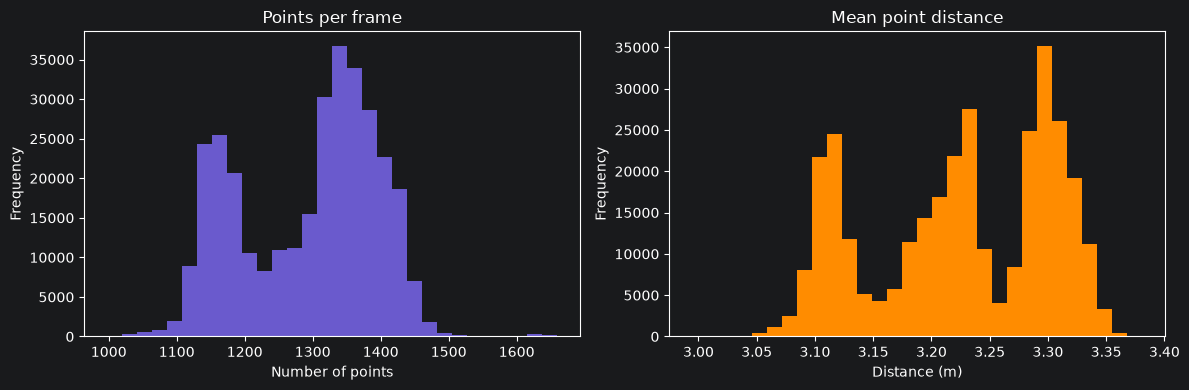

In [26]:
print(f"Analyzed frames: {len(quality_summary)}")
print(f"Frames with invalid points: {(quality_summary['invalid_points'] > 0).sum()}")
print(f"Empty frames: {(quality_summary['points'] == 0).sum()}")
print("LiDAR coordinate and distance units: meters (m)")
print()
print("Point-count and distance summary:")
display(quality_summary[["points", "finite_points", "mean_distance", "max_distance"]].describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
quality_summary["points"].plot.hist(bins=30, ax=axes[0], color="slateblue")
axes[0].set_title("Points per frame")
axes[0].set_xlabel("Number of points")
quality_summary["mean_distance"].plot.hist(bins=30, ax=axes[1], color="darkorange")
axes[1].set_title("Mean point distance")
axes[1].set_xlabel("Distance (m)")
fig.tight_layout()
plt.show()

## 4 - LiDAR videos for all classes

In [ ]:
from IPython.display import HTML, display
from matplotlib.animation import FuncAnimation, PillowWriter

VIDEO_DIR = DATA_DIR / "mmfi_class_videos"
VIDEO_DIR.mkdir(parents=True, exist_ok=True)
VIDEO_FRAME_STEP = 2
VIDEO_MAX_POINTS = 300
class_video_paths = {}

for action, row in representative_sequences.iterrows():
    sequence_dir = Path(row["path"])
    frame_paths = sorted((sequence_dir / "lidar").glob("frame*.bin"))[::VIDEO_FRAME_STEP]
    video_points = [
        load_lidar_frame(path)[::max(1, len(load_lidar_frame(path)) // VIDEO_MAX_POINTS)]
        for path in frame_paths
    ]

    all_points = np.concatenate(video_points)
    axis_min = all_points.min(axis=0)
    axis_max = all_points.max(axis=0)
    axis_margin = 0.1 * (axis_max - axis_min)

    figure = plt.figure(figsize=(7, 6))
    axis = figure.add_subplot(111, projection="3d")
    point_plot = axis.scatter([], [], [], s=5, alpha=0.5, color="steelblue")
    axis.set_xlim(axis_min[0] - axis_margin[0], axis_max[0] + axis_margin[0])
    axis.set_ylim(axis_min[1] - axis_margin[1], axis_max[1] + axis_margin[1])
    axis.set_zlim(axis_min[2] - axis_margin[2], axis_max[2] + axis_margin[2])
    axis.set_xlabel("X (m)")
    axis.set_ylabel("Y (m)")
    axis.set_zlabel("Z (m)")
    axis.view_init(elev=20, azim=-60)

    def update_class_video(frame_index):
        points = video_points[frame_index]
        point_plot._offsets3d = (points[:, 0], points[:, 1], points[:, 2])
        axis.set_title(f"{action}: {action_names[action]} - frame {frame_index + 1}/{len(video_points)}")
        return [point_plot]

    class_animation = FuncAnimation(
        figure,
        update_class_video,
        frames=len(video_points),
        interval=67,
        blit=False,
    )
    output_path = VIDEO_DIR / f"mmfi_{action}.gif"
    class_animation.save(output_path, writer=PillowWriter(fps=15))
    plt.close(figure)
    class_video_paths[action] = output_path

print(f"Generated {len(class_video_paths)} videos in {VIDEO_DIR.resolve()}")

In [45]:
video_cards = []
for action, video_path in class_video_paths.items():
    video_src = Path(video_path).as_posix()
    video_cards.append(
        f"<div><b>{action}: {action_names[action]}</b>"
        f"<br><img src='{video_src}' width='600'></div>"
    )

display(
    HTML(
        "<div style='display:grid;grid-template-columns:repeat(1,1fr);gap:12px;'>"
        + "".join(video_cards)
        + "</div>"
    )
)

# 260